# Análisis del comportamiento y la fidelización de clientes en plataformas de comercio electrónico
### *Customer Behavior & Retention Analysis*

**Curso:** Programación II — Ciencia de Datos

**Integrantes:** Mafe · Artur · Wendy

**Fuente de datos:** [Ecommerce Customer Behavior Dataset – Kaggle](https://www.kaggle.com/datasets/srisyra02/ecommerce-customer-behavior-dataset)

---

**Pregunta central:** ¿Qué características y comportamientos de los clientes están relacionados con su permanencia o abandono de una plataforma de comercio electrónico?

**Objetivo general:** Analizar los patrones de comportamiento, interacción y transacciones de los clientes para identificar factores asociados con su fidelización y abandono.

**Preguntas guía:**
- ¿Qué tipo de clientes tienen mayor tendencia a abandonar la plataforma?
- ¿Los clientes que interactúan con mayor frecuencia permanecen más?
- ¿Existe relación entre la experiencia del cliente (servicio al cliente, carrito) y la fidelización?
- ¿Qué grupos de clientes generan mayor valor para la empresa?
- ¿Qué características tienen los clientes más comprometidos?

**Contenido del notebook**
1. Carga e inspección inicial de los datos
2. Manejo de datos faltantes
3. Identificación y tratamiento de outliers
4. Valores inconsistentes, texto y duplicados
5. Creación de variables
6. Filtrado y condiciones con Pandas (5 resultados)
7. Agrupación con `groupby` (5 resultados)
8. Visualizaciones (5 gráficos)
9. Conclusiones

## Instalación de librerías

> **Ejecutar solo la primera vez en cada computador.**
> La siguiente celda instala las librerías necesarias para el análisis (pandas, numpy, matplotlib y seaborn).
> Si las librerías ya están instaladas, esta celda se puede omitir.

In [16]:
%pip install pandas numpy matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## 1. Carga e inspección inicial de los datos

In [18]:
datos = pd.read_csv("ecommerce-dataset.csv")
datos.head()

,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,Total_Purchases,Average_Order_Value,Days_Since_Last_Purchase,Discount_Usage_Rate,Returns_Rate,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned,Signup_Quarter
0,43.0,Male,France,Marseille,2.9,14,27.4,6.0,50.6,3.0,9.0,94.72,34.0,46.40,2.0,17.9,9.0,4.0,16.3,20.8,1.0,953.33,2278.0,0,Q1
1,36.0,Male,UK,Manchester,1.6,15,42.7,10.3,37.7,1.0,19.5,82.45,71.0,57.96,9.2,42.8,7.0,3.0,NaN,23.3,3.0,1067.47,3028.0,0,Q4
2,45.0,Female,Canada,Vancouver,2.9,10,24.8,1.6,70.9,1.0,9.1,165.52,11.0,12.24,11.5,0.0,4.0,1.0,NaN,8.8,NaN,1289.75,2317.0,0,Q4
3,56.0,Female,USA,New York,2.6,10,38.4,14.8,41.7,9.0,15.0,147.33,47.0,44.10,5.4,41.4,2.0,5.0,85.9,31.0,3.0,2340.92,2674.0,0,Q1
4,35.0,Male,India,Delhi,3.1,29,51.4,NaN,19.1,9.0,32.5,141.30,73.0,25.20,5.5,37.9,1.0,11.0,83.0,50.4,4.0,3041.29,5354.0,0,Q4


### 1.1 Tamaño del conjunto de datos

In [19]:
filas, columnas = datos.shape
print(f"El conjunto de datos tiene {filas} registros (clientes) y {columnas} columnas (variables).")

El conjunto de datos tiene 50000 registros (clientes) y 25 columnas (variables).


### 1.2 Tipos de variables

In [20]:
datos.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 25 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Age                            47505 non-null  float64
 1   Gender                         50000 non-null  str    
 2   Country                        50000 non-null  str    
 3   City                           50000 non-null  str    
 4   Membership_Years               50000 non-null  float64
 5   Login_Frequency                50000 non-null  int64  
 6   Session_Duration_Avg           46601 non-null  float64
 7   Pages_Per_Session              47000 non-null  float64
 8   Cart_Abandonment_Rate          50000 non-null  float64
 9   Wishlist_Items                 46000 non-null  float64
 10  Total_Purchases                50000 non-null  float64
 11  Average_Order_Value            50000 non-null  float64
 12  Days_Since_Last_Purchase       47000 non-null  float64
 1

Además del tipo que asigna Pandas, clasificamos cada variable según su **naturaleza estadística** para comprobar los requisitos del proyecto:

In [21]:
categoricas = ["Gender", "Country", "City", "Signup_Quarter", "Churned"]

discretas = ["Login_Frequency", "Wishlist_Items", "Total_Purchases", "Days_Since_Last_Purchase",
             "Customer_Service_Calls", "Product_Reviews_Written", "Payment_Method_Diversity"]

continuas = ["Age", "Membership_Years", "Session_Duration_Avg", "Pages_Per_Session",
             "Cart_Abandonment_Rate", "Average_Order_Value", "Discount_Usage_Rate", "Returns_Rate",
             "Email_Open_Rate", "Social_Media_Engagement_Score", "Mobile_App_Usage",
             "Lifetime_Value", "Credit_Balance"]

print(f"Registros: {len(datos)}  (requisito: más de 1000)")
print(f"Variables categóricas: {len(categoricas)}  (requisito: más de 2) -> {categoricas}")
print(f"Variables numéricas discretas: {len(discretas)}  (requisito: más de 2)")
print(f"Variables numéricas continuas: {len(continuas)}  (requisito: más de 2)")

Registros: 50000  (requisito: más de 1000)
Variables categóricas: 5  (requisito: más de 2) -> ['Gender', 'Country', 'City', 'Signup_Quarter', 'Churned']
Variables numéricas discretas: 7  (requisito: más de 2)
Variables numéricas continuas: 13  (requisito: más de 2)


> **Conclusión:** El dataset cumple con todos los requisitos del proyecto: tiene **50.000 registros**, 5 variables categóricas (incluyendo `Churned`, que indica si el cliente abandonó: 1 = sí, 0 = no), 7 numéricas discretas y 13 numéricas continuas.
> Pandas lee muchas variables discretas como `float64` porque contienen valores faltantes (`NaN` es un número decimal); esto se corrige después de la limpieza.

### 1.3 Descripción estadística

In [22]:
datos.describe().round(2)

,Age,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,Total_Purchases,Average_Order_Value,Days_Since_Last_Purchase,Discount_Usage_Rate,Returns_Rate,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned
count,47505.00,50000.00,50000.00,46601.00,47000.00,50000.00,46000.00,50000.00,50000.00,47000.00,46500.00,45509.00,47472.00,49832.00,46500.00,44000.00,45000.00,47500.00,50000.00,44500.00,50000.00
mean,37.80,2.98,11.62,27.66,8.74,57.08,4.30,13.11,123.12,29.79,42.00,6.68,20.94,5.68,2.85,29.36,19.37,2.35,1440.63,1966.23,0.29
std,11.83,2.06,7.81,10.87,3.78,16.28,3.19,7.02,175.57,29.70,21.37,6.14,14.25,2.68,2.33,20.57,9.42,1.11,907.25,1225.07,0.45
min,5.00,0.10,0.00,1.00,1.00,0.00,0.00,-13.00,26.38,0.00,0.24,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00
25%,29.00,1.40,6.00,19.70,6.00,46.40,2.00,8.00,87.05,9.00,25.30,2.90,9.90,4.00,1.00,13.20,12.50,2.00,789.82,1049.00,0.00
50%,38.00,2.50,11.00,26.80,8.40,58.10,4.00,12.00,112.97,21.00,40.20,5.40,19.70,5.00,2.00,27.60,18.60,2.00,1243.42,1896.00,0.00
75%,46.00,4.00,17.00,34.70,11.20,68.70,6.00,17.00,144.44,41.00,57.00,9.10,30.40,7.00,4.00,43.10,25.50,3.00,1874.00,2791.00,1.00
max,200.00,10.00,46.00,75.60,24.10,143.74,28.00,128.70,9666.38,287.00,116.64,99.62,91.70,21.00,21.00,100.00,61.90,5.00,8987.24,7197.00,1.00


In [23]:
datos.describe(include=["object", "string"])

,Gender,Country,City,Signup_Quarter
count,50000,50000,50000,50000
unique,3,8,40,4
top,Female,USA,Houston,Q3
freq,25116,17384,3549,12558


> **Conclusión:** La descripción estadística ya muestra **valores sospechosos** que se tratarán más adelante:
> - `Age` tiene un mínimo de 5 años y un máximo de 200 años (edades imposibles para un cliente).
> - `Total_Purchases` tiene valores **negativos** (mínimo −13) y decimales, aunque el número de compras debe ser un entero positivo.
> - `Cart_Abandonment_Rate` y `Discount_Usage_Rate` superan el 100 %, lo cual no es posible en un porcentaje.
> - `Average_Order_Value` tiene una media (123) muy por encima de la mediana (113) y un máximo de 9.666, lo que indica valores extremos.

In [24]:
# Proporción de clientes que abandonaron vs. que permanecen
datos["Churned"].value_counts(normalize=True).mul(100).round(1)

Churned
0    71.1
1    28.9
Name: proportion, dtype: float64

> **Conclusión:** El **28,9 %** de los clientes abandonó la plataforma y el **71,1 %** permanece. Esta es la tasa de abandono de referencia con la que compararemos los distintos grupos de clientes.

---
## 2. Manejo de datos faltantes

In [25]:
faltantes = pd.DataFrame({
    "Nulos": datos.isnull().sum(),
    "Porcentaje (%)": (datos.isnull().sum() / len(datos) * 100).round(2)
})
faltantes[faltantes["Nulos"] > 0].sort_values("Nulos", ascending=False)

,Nulos,Porcentaje (%)
Social_Media_Engagement_Score,6000,12.00
Credit_Balance,5500,11.00
Mobile_App_Usage,5000,10.00
Returns_Rate,4491,8.98
Wishlist_Items,4000,8.00
Discount_Usage_Rate,3500,7.00
Product_Reviews_Written,3500,7.00
Session_Duration_Avg,3399,6.80
Pages_Per_Session,3000,6.00
Days_Since_Last_Purchase,3000,6.00


In [26]:
filas_con_nulos = datos.isnull().any(axis=1).sum()
print(f"Filas con al menos un valor faltante: {filas_con_nulos} ({filas_con_nulos / len(datos) * 100:.1f} % del total)")

Filas con al menos un valor faltante: 32017 (64.0 % del total)


### 2.1 Mapa de calor de valores faltantes (antes)

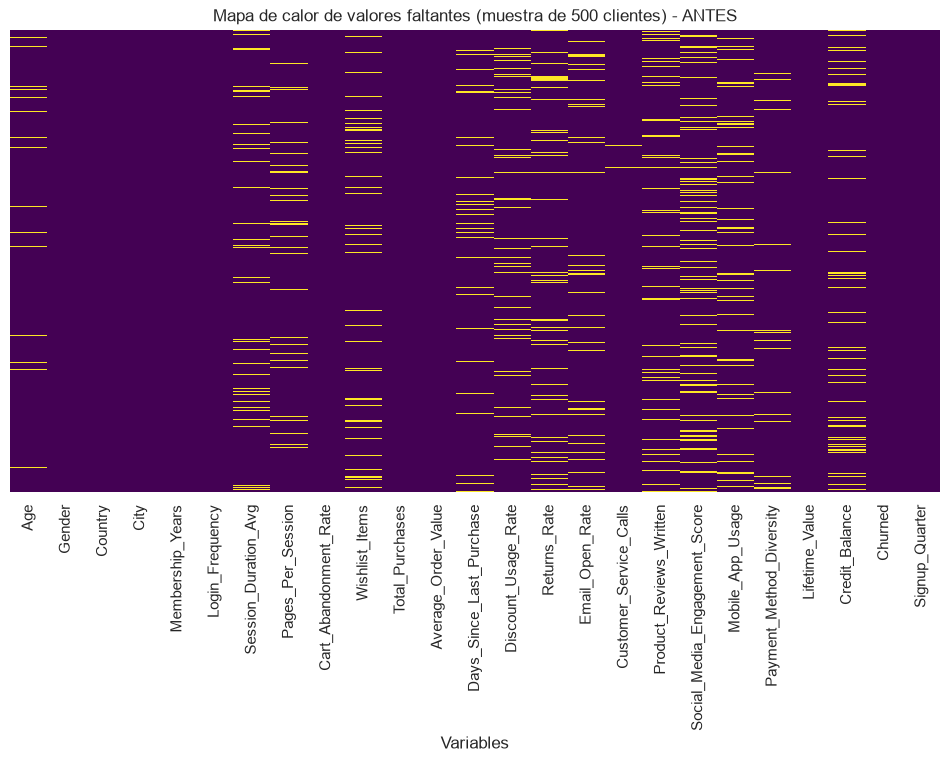

In [27]:
# Se toma una muestra de 500 clientes para que el mapa de calor sea legible
muestra = datos.sample(500, random_state=42)

plt.figure(figsize=(12, 6))
sns.heatmap(muestra.isnull(), cbar=False, cmap="viridis", yticklabels=False)
plt.title("Mapa de calor de valores faltantes (muestra de 500 clientes) - ANTES")
plt.xlabel("Variables")
plt.show()

### 2.2 Decisión: ¿eliminar o imputar?

- **No eliminamos filas:** el **64 %** de los clientes tiene al menos un dato faltante. Si usáramos `dropna()` perderíamos más de la mitad de la base de datos.
- **No eliminamos columnas:** ninguna variable supera el **12 %** de faltantes, por lo que todas conservan información útil.
- **Imputamos con la mediana:** varias variables tienen valores extremos (ej. `Age` y `Average_Order_Value`), y la mediana **no se ve afectada por los outliers**, a diferencia de la media.
- En las variables **discretas** (conteos), la mediana se redondea para que el valor imputado siga siendo un número entero.
- Las variables categóricas **no tienen faltantes**, así que no requieren imputación.

In [28]:
columnas_con_nulos = datos.columns[datos.isnull().any()]

for columna in columnas_con_nulos:
    mediana = datos[columna].median()
    if columna in discretas:
        mediana = round(mediana)
    datos[columna] = datos[columna].fillna(mediana)
    print(f"{columna}: faltantes imputados con la mediana = {mediana}")

Age: faltantes imputados con la mediana = 38.0
Session_Duration_Avg: faltantes imputados con la mediana = 26.8
Pages_Per_Session: faltantes imputados con la mediana = 8.4
Wishlist_Items: faltantes imputados con la mediana = 4
Days_Since_Last_Purchase: faltantes imputados con la mediana = 21
Discount_Usage_Rate: faltantes imputados con la mediana = 40.2
Returns_Rate: faltantes imputados con la mediana = 5.4
Email_Open_Rate: faltantes imputados con la mediana = 19.7
Customer_Service_Calls: faltantes imputados con la mediana = 5
Product_Reviews_Written: faltantes imputados con la mediana = 2
Social_Media_Engagement_Score: faltantes imputados con la mediana = 27.6
Mobile_App_Usage: faltantes imputados con la mediana = 18.6
Payment_Method_Diversity: faltantes imputados con la mediana = 2
Credit_Balance: faltantes imputados con la mediana = 1896.0


### 2.3 Mapa de calor de valores faltantes (después)

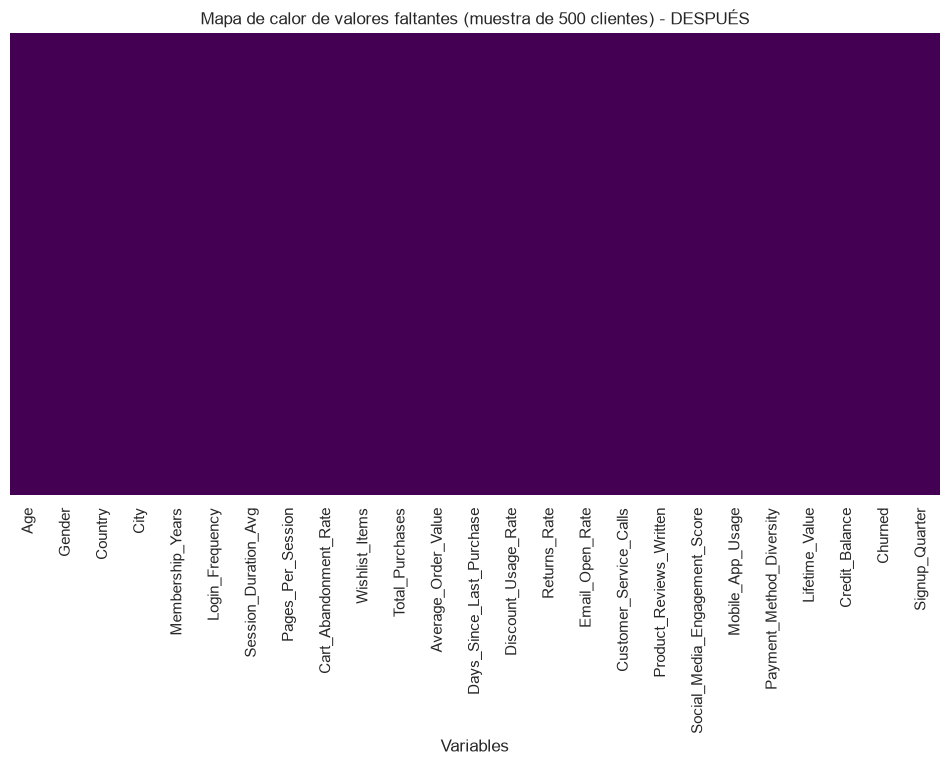

Total de valores faltantes después de la imputación: 0


In [29]:
plt.figure(figsize=(12, 6))
sns.heatmap(datos.sample(500, random_state=42).isnull(), cbar=False, cmap="viridis", yticklabels=False)
plt.title("Mapa de calor de valores faltantes (muestra de 500 clientes) - DESPUÉS")
plt.xlabel("Variables")
plt.show()

print(f"Total de valores faltantes después de la imputación: {datos.isnull().sum().sum()}")

> **Conclusión:** Se imputaron los faltantes de 14 variables con su mediana. El mapa de calor ya no muestra espacios vacíos y la base conserva los **50.000 clientes**, lo que permite analizar a todos los clientes sin perder información.

---
## 3. Identificación de outliers

---
## 4. Tratamiento de valores inconsistentes en texto y duplicados

---
## 5. Creación de variables

---
## 6. Filtrado y condiciones con Pandas

---
## 7. Agrupación con `groupby`

---
## 8. Visualizaciones

---
## 9. Conclusiones finales